# ZIP and ZIC Profitability Benchmark

Compares homogeneous ZIP and ZIC markets across 20 sessions per strategy. The saved output reports a Welch unequal-variance t-test. Running the code launches 40 BSE sessions and creates temporary balance files, which are removed after use.



Results: 
ZIP mean profit: 104.23 (std: 9.24)
ZIC mean profit: 93.82 (std: 13.74)
T-statistic: 2.7409
P-value: 9.7816e-03
Reject the null hypothesis: ZIP earns significantly higher mean profit than ZIC.


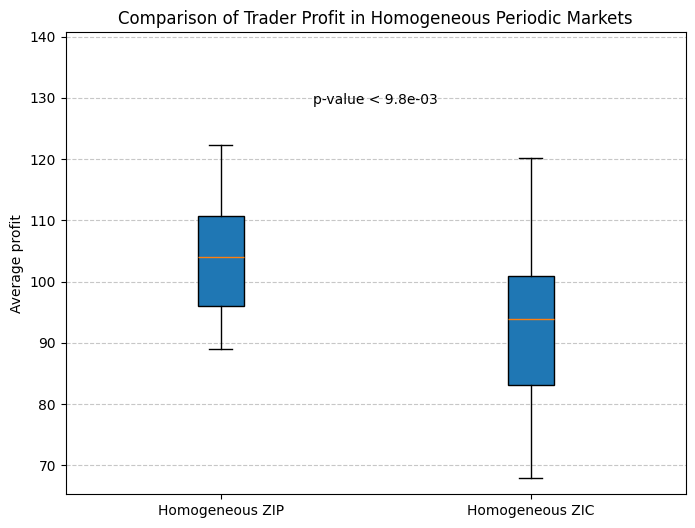

In [ ]:
import bse
import csv
import random
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

def run_homogeneous_session(trader_type, session_id):
    """
    Run a homogeneous market. Returns average profit.
    """
    # Equilibrium price is 100.
    sup_range = (50, 150)
    dem_range = (50, 150)
    
    start_time = 0
    end_time = 60 * 3  
    
    # Random scheduling draws buyer values and seller costs from the specified range.
    supply_schedule = [{'from': start_time, 'to': end_time, 'ranges': [sup_range], 'stepmode': 'random'}]
    demand_schedule = [{'from': start_time, 'to': end_time, 'ranges': [dem_range], 'stepmode': 'random'}]
    
    # Periodic
    order_sched = {'sup': supply_schedule, 'dem': demand_schedule,
                   'interval': 15, 'timemode': 'periodic'}
    
    # trader population
    num_traders = 10
    buyers_spec = [(trader_type, num_traders)]
    sellers_spec = [(trader_type, num_traders)]
    traders_spec = {'sellers': sellers_spec, 'buyers': buyers_spec}
    
    # Set output
    dump_flags = {'dump_blotters': False, 'dump_lobs': False, 'dump_strats': False,
                  'dump_avgbals': True, 'dump_tape': False}
    
    # Run BSE 
    bse.market_session(session_id, start_time, end_time, traders_spec, order_sched, dump_flags, False)
    
    filename = session_id + '_avg_balance.csv'
    avg_profit = 0
    
    try:
        with open(filename, 'r') as csvfile:
            lines = list(csv.reader(csvfile))
            if len(lines) > 0:
                last_line = lines[-1]
                for i, col in enumerate(last_line):
                    if col.strip() == trader_type:
                        avg_profit = float(last_line[i+3]) # 3rd column after Type is AvgProfit
                        break
    except Exception as e:
        print(f"Error reading {filename}: {e}")
    finally:
        # Clean up
        if os.path.exists(filename):
            os.remove(filename)
            
    return avg_profit

# Run the experiment.
n_trials = 20
zip_profits = []
zic_profits = []

for i in range(n_trials):
    zip_profits.append(run_homogeneous_session('ZIP', f"Q1_ZIP_{i}"))
    zic_profits.append(run_homogeneous_session('ZIC', f"Q1_ZIC_{i}"))
   


# Welch's unequal-variance t-test.
t_stat, p_value = stats.ttest_ind(zip_profits, zic_profits, equal_var=False)

print("\nResults: ")
print(f"ZIP mean profit: {np.mean(zip_profits):.2f} (std: {np.std(zip_profits):.2f})")
print(f"ZIC mean profit: {np.mean(zic_profits):.2f} (std: {np.std(zic_profits):.2f})")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05 and t_stat > 0:
    print("Reject the null hypothesis: ZIP earns significantly higher mean profit than ZIC.")
elif t_stat < 0:
    print("Unexpected result, please check.")
else:
    print("Fail to reject the null hypothesis.")

# Visualise the profit distributions.
plt.figure(figsize=(8, 6))


plt.boxplot([zip_profits, zic_profits], tick_labels=['Homogeneous ZIP', 'Homogeneous ZIC'], patch_artist=True)

plt.title('ZIP and ZIC Profitability in Homogeneous Periodic Markets')
plt.ylabel('Average profit')
plt.grid(axis='y', linestyle='--', alpha=0.7)

y_max = max(max(zip_profits), max(zic_profits))

plt.text(1.5, y_max * 1.05, f'p-value < {p_value:.1e}', ha='center', va='bottom')

plt.ylim(top=y_max*1.15)

plt.show()